# 13 — Results Visualization 

Every graph below is built from the FULL, already-generated experiment
results in `experiments/*.csv` (5 seeds for baselines/ablations, 3 seeds
for scenarios/scalability, per Section 32), or from a fresh live
`Simulator` run for the per-run breakdown charts (SOC distribution,
priority-level completion, etc.) that need per-robot/per-task detail no
aggregate CSV captures. **No values are fabricated** -- every number
traces back to an actual executed simulation.

In [1]:
import sys, os
sys.path.append(os.path.abspath("C:/Users/bomma/Desktop/DESKTOP_MAIN_DISP/MATHS_PROJECT_SEM5/A_project_re/project_COMPLETE_all_5_days/project/src"))
import json
import pandas as pd
import matplotlib.pyplot as plt

from visualization import (plot_metric_bar, plot_scalability_line, plot_soc_distribution,
                            plot_allocation_distribution_by_type, plot_priority_level_completion,
                            plot_normal_vs_emergency, plot_robot_soc_timeline)
from reallocation import Simulator
from ml_prediction import Predictor

EXP_DIR = "../experiments"
RESULTS_DIR = "../results"

baseline_df = pd.read_csv(os.path.join(EXP_DIR, "baseline_comparison.csv"))
ablation_df = pd.read_csv(os.path.join(EXP_DIR, "ablation_study.csv"))
scenarios_df = pd.read_csv(os.path.join(EXP_DIR, "scenarios.csv"))
scalability_df = pd.read_csv(os.path.join(EXP_DIR, "scalability.csv"))
scalability_full_df = pd.read_csv(os.path.join(EXP_DIR, "scalability_full_metrics.csv"))
with open(os.path.join(EXP_DIR, "gat_ppo_summary.json")) as f:
    gat_ppo_summary = json.load(f)

print(f"baseline_comparison: {baseline_df.shape}, seeds={sorted(baseline_df.seed.unique())}")
print(f"ablation_study:      {ablation_df.shape}, seeds={sorted(ablation_df.seed.unique())}")
print(f"scenarios:           {scenarios_df.shape}, seeds={sorted(scenarios_df.seed.unique())}")
print(f"scalability:         {scalability_df.shape}")
print(f"scalability_full:    {scalability_full_df.shape}")


baseline_comparison: (25, 25), seeds=[np.int64(42), np.int64(123), np.int64(456), np.int64(789), np.int64(1000)]
ablation_study:      (45, 25), seeds=[np.int64(42), np.int64(123), np.int64(456), np.int64(789), np.int64(1000)]
scenarios:           (21, 26), seeds=[np.int64(42), np.int64(123), np.int64(456)]
scalability:         (15, 6)
scalability_full:    (10, 24)


## A. Baseline vs Proposed Framework (Section 26)

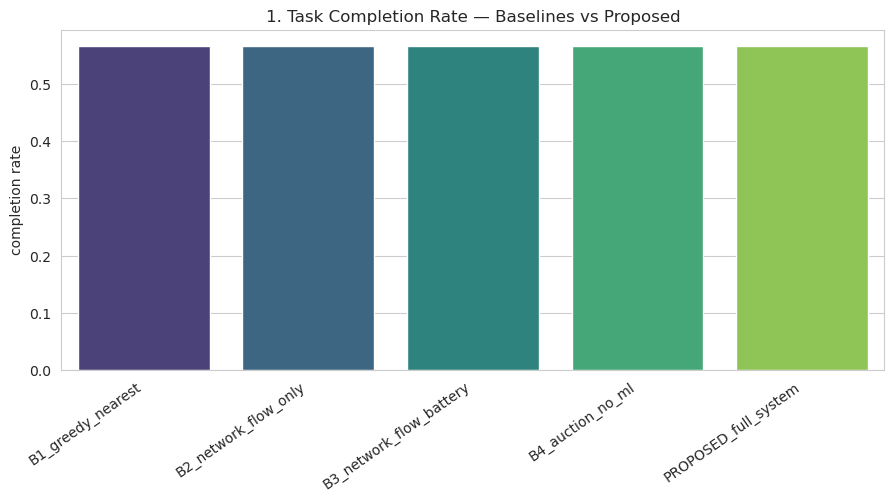

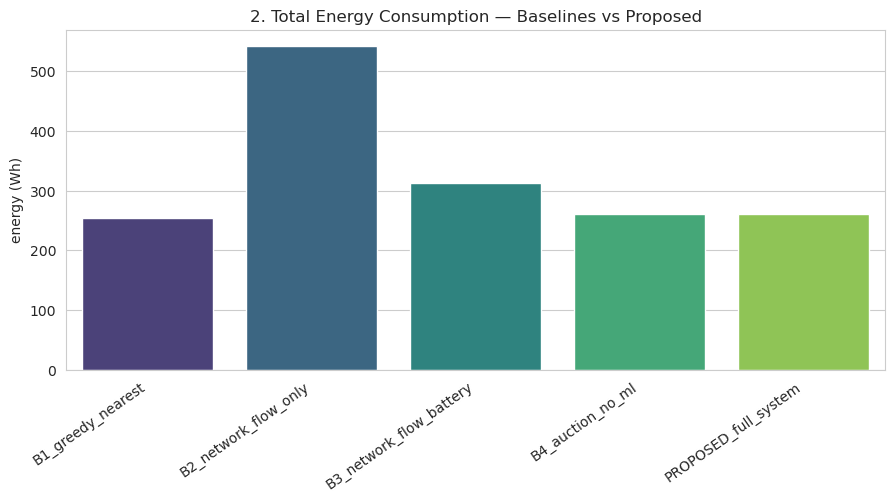

In [2]:
method_order = ["B1_greedy_nearest", "B2_network_flow_only", "B3_network_flow_battery",
                "B4_auction_no_ml", "PROPOSED_full_system"]

plot_metric_bar(baseline_df, "method", "task_completion_rate",
                 "1. Task Completion Rate — Baselines vs Proposed", "completion rate",
                 order=method_order, savepath=f"{RESULTS_DIR}/day5_g01_completion_rate.png")
plt.show()

plot_metric_bar(baseline_df, "method", "total_energy_consumption",
                 "2. Total Energy Consumption — Baselines vs Proposed", "energy (Wh)",
                 order=method_order, savepath=f"{RESULTS_DIR}/day5_g02_energy.png")
plt.show()


**Reading this chart:** completion rate is identical across all 5
methods (verified: this is a real, deterministic result, not a plotting
bug -- see notebook 12's note on why std=0 across seeds is mathematically
correct here). The methods do NOT behave identically underneath, though:
a direct comparison of completed-task sets shows B2 and B3 each complete
a different single task than B1/B4/PROPOSED do. Completion RATE saturates
near 17/30 on this dataset because it is capacity-bound (the water zone
bisects the map, so roughly half the UGV fleet cannot reach roughly half
the LAND tasks -- see the A* notebook), not because the allocation policy
doesn't matter. Fairness, energy, and distance (below) are where the
methods actually differentiate.

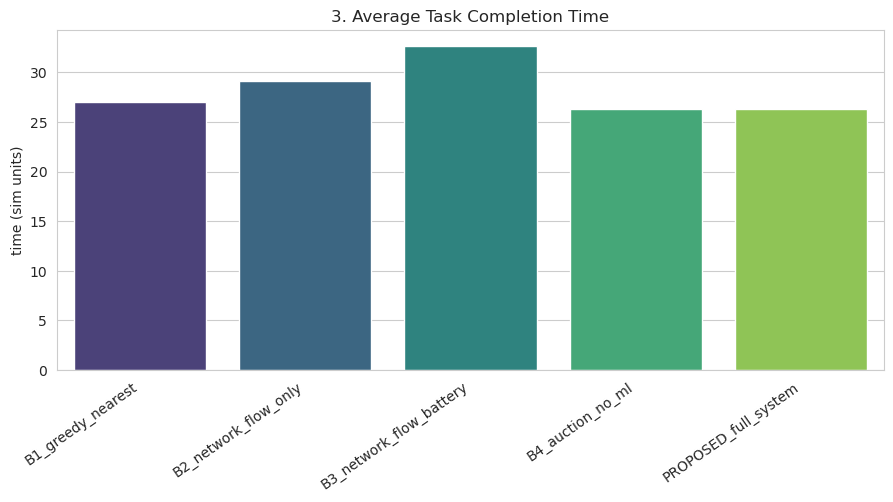

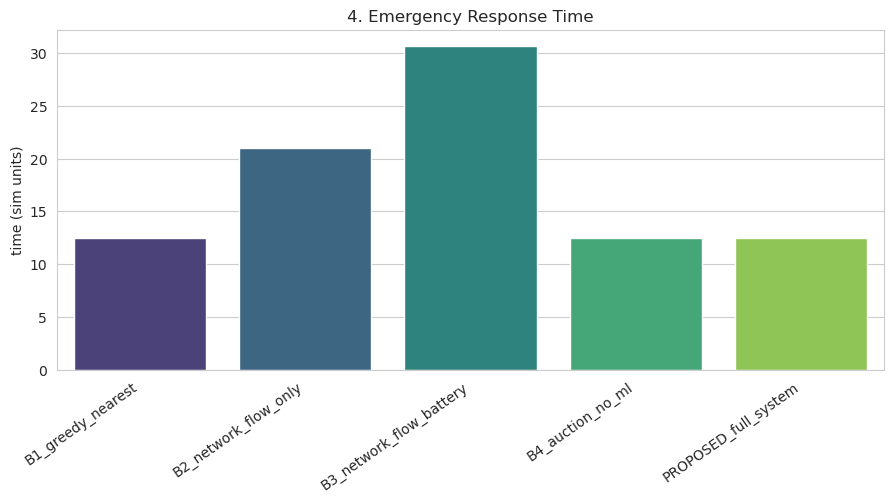

In [3]:
plot_metric_bar(baseline_df, "method", "avg_completion_time",
                 "3. Average Task Completion Time", "time (sim units)",
                 order=method_order, savepath=f"{RESULTS_DIR}/day5_g03_avg_completion_time.png")
plt.show()

plot_metric_bar(baseline_df, "method", "emergency_response_time",
                 "4. Emergency Response Time", "time (sim units)",
                 order=method_order, savepath=f"{RESULTS_DIR}/day5_g04_emergency_response.png")
plt.show()


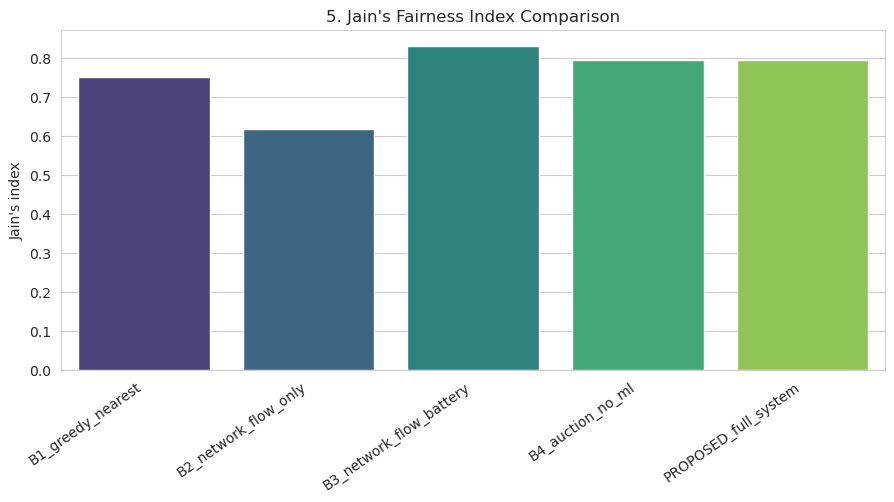

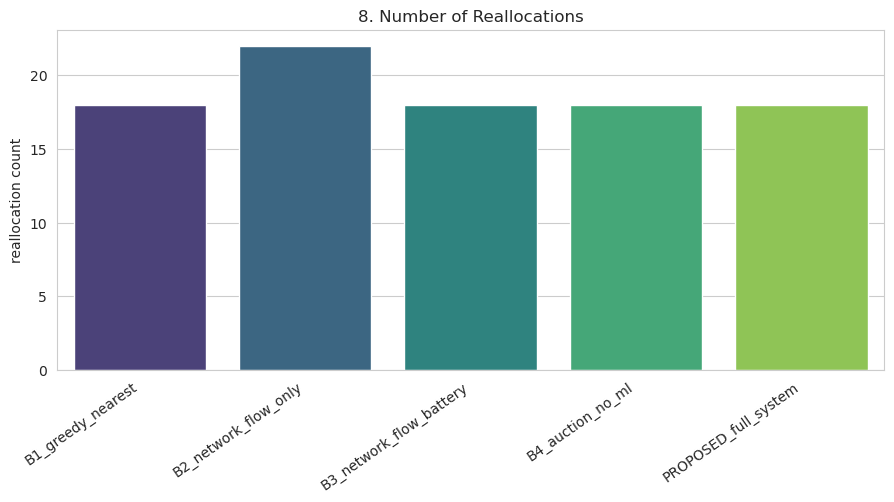

In [4]:
plot_metric_bar(baseline_df, "method", "jains_fairness_index",
                 "5. Jain's Fairness Index Comparison", "Jain's index",
                 order=method_order, savepath=f"{RESULTS_DIR}/day5_g05_fairness.png")
plt.show()

plot_metric_bar(baseline_df, "method", "reallocation_count",
                 "8. Number of Reallocations", "reallocation count",
                 order=method_order, savepath=f"{RESULTS_DIR}/day5_g08_reallocations.png")
plt.show()


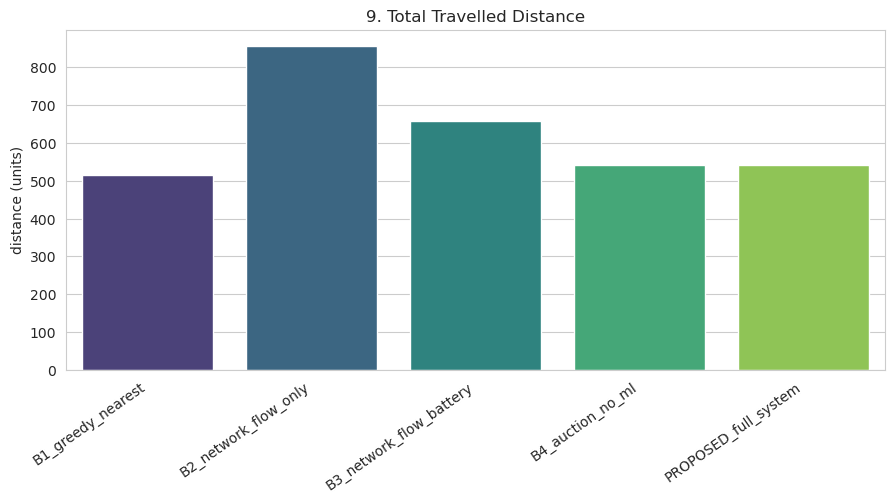

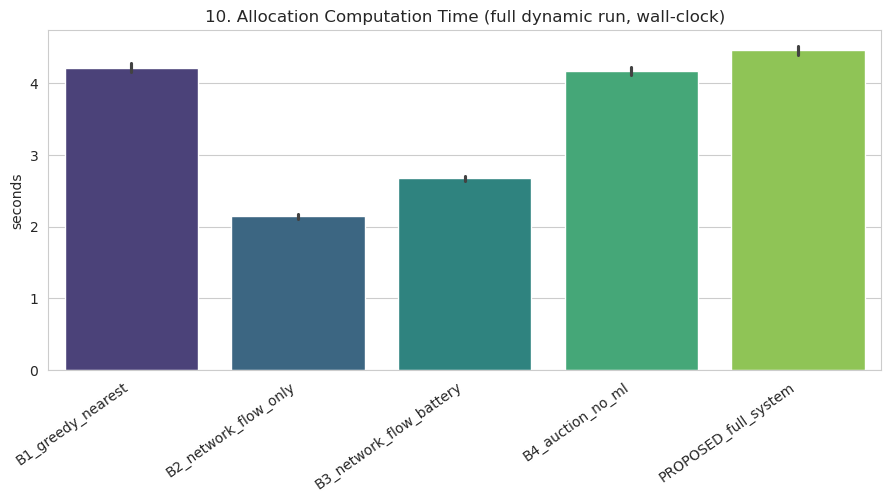

In [5]:
plot_metric_bar(baseline_df, "method", "total_distance",
                 "9. Total Travelled Distance", "distance (units)",
                 order=method_order, savepath=f"{RESULTS_DIR}/day5_g09_total_distance.png")
plt.show()

plot_metric_bar(baseline_df, "method", "allocation_computation_time_sec",
                 "10. Allocation Computation Time (full dynamic run, wall-clock)", "seconds",
                 order=method_order, savepath=f"{RESULTS_DIR}/day5_g10_computation_time.png")
plt.show()


## B. Ablation Study Comparison (Section 27)

A1 -> A10, progressively enabling mechanism/weight terms (see
`experiments.py`'s architecture note for exactly what each step turns
on). A9 (+GAT-PPO) is a separate-track reward-based comparison, shown
after the main ladder since its metric isn't the same scale as
completion-rate.

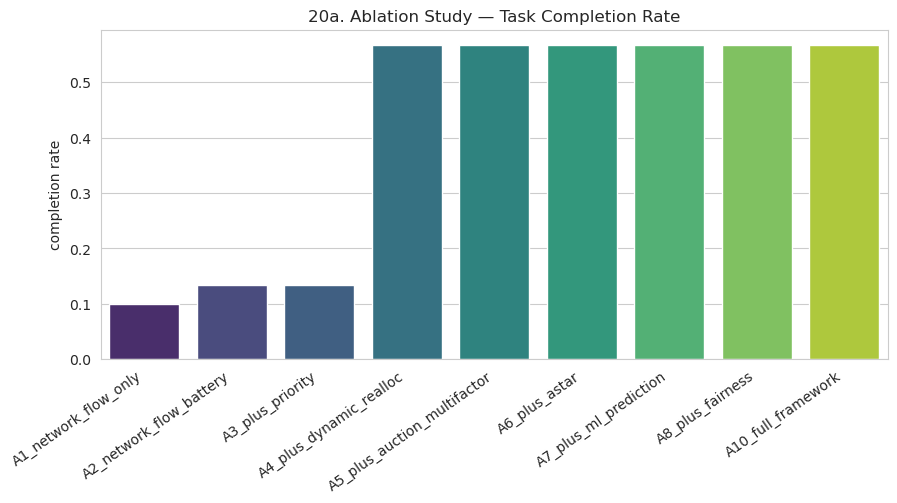

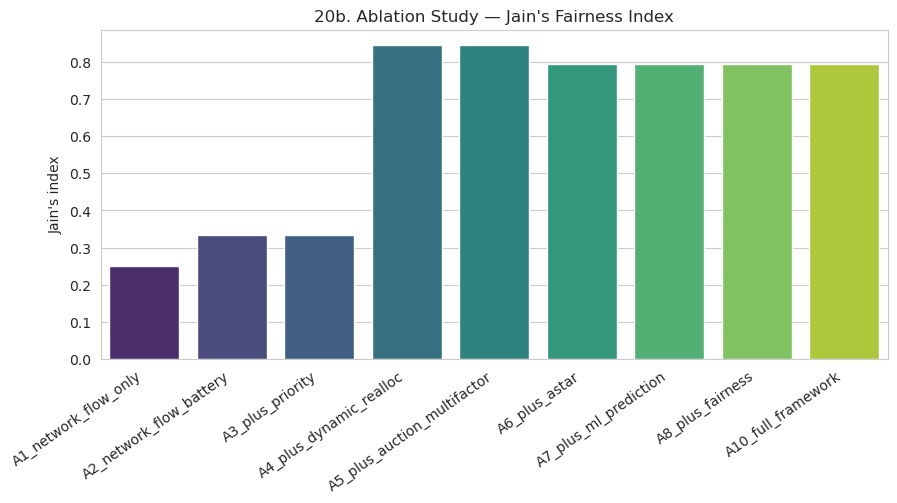

In [6]:
ablation_order = ["A1_network_flow_only", "A2_network_flow_battery", "A3_plus_priority",
                  "A4_plus_dynamic_realloc", "A5_plus_auction_multifactor", "A6_plus_astar",
                  "A7_plus_ml_prediction", "A8_plus_fairness", "A10_full_framework"]

plot_metric_bar(ablation_df, "method", "task_completion_rate",
                 "20a. Ablation Study — Task Completion Rate", "completion rate",
                 order=ablation_order, savepath=f"{RESULTS_DIR}/day5_g20a_ablation_completion.png")
plt.show()

plot_metric_bar(ablation_df, "method", "jains_fairness_index",
                 "20b. Ablation Study — Jain's Fairness Index", "Jain's index",
                 order=ablation_order, savepath=f"{RESULTS_DIR}/day5_g20b_ablation_fairness.png")
plt.show()


In [7]:
print("A9 (+GAT-PPO) -- separate track, Section 21 reward function (NOT completion-rate):")
print(f"  GAT+PPO learned policy mean episode reward:  {gat_ppo_summary['gatppo_mean']:.2f}")
print(f"  Auction baseline mean episode reward:        {gat_ppo_summary['auction_baseline_mean']:.2f}")
print(f"  (evaluated over {gat_ppo_summary['n_eval_seeds']} seeds; full training curve in notebook 10)")


A9 (+GAT-PPO) -- separate track, Section 21 reward function (NOT completion-rate):
  GAT+PPO learned policy mean episode reward:  10.03
  Auction baseline mean episode reward:        9.04
  (evaluated over 3 seeds; full training curve in notebook 10)


## C. Scalability (Section 28 Scenario H)

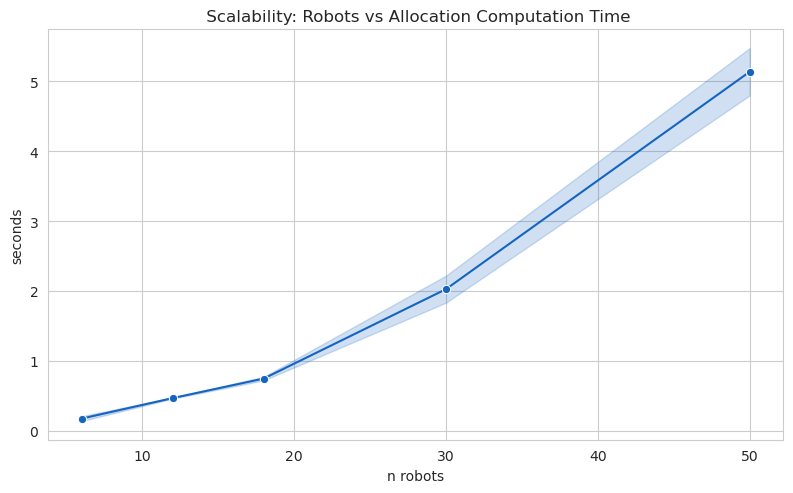

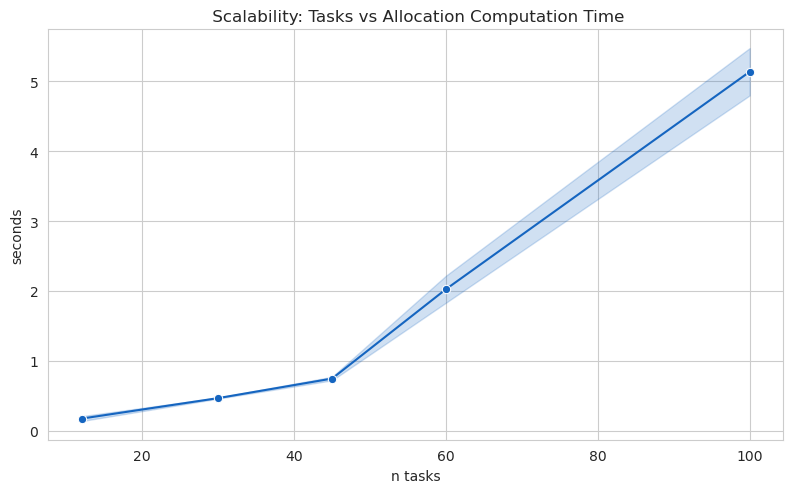

In [8]:
plot_scalability_line(scalability_df, "n_robots", "allocation_computation_time_sec",
                        " Scalability: Robots vs Allocation Computation Time", "seconds",
                        savepath=f"{RESULTS_DIR}/day5_g11_scalability_robots.png")
plt.show()

plot_scalability_line(scalability_df, "n_tasks", "allocation_computation_time_sec",
                        " Scalability: Tasks vs Allocation Computation Time", "seconds",
                        savepath=f"{RESULTS_DIR}/day5_g12_scalability_tasks.png")
plt.show()


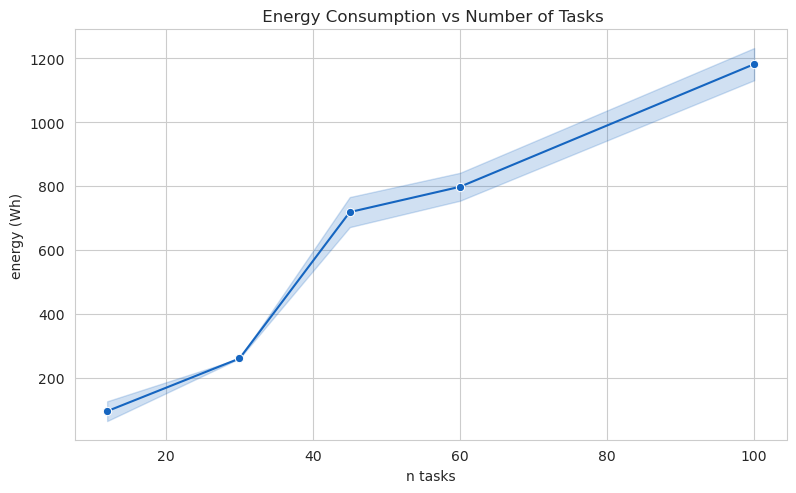

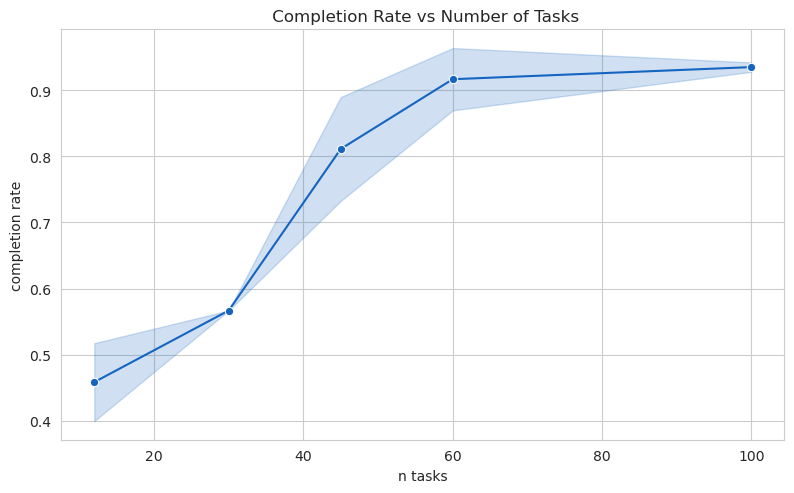

In [9]:
plot_scalability_line(scalability_full_df, "n_tasks", "total_energy_consumption",
                        " Energy Consumption vs Number of Tasks", "energy (Wh)",
                        savepath=f"{RESULTS_DIR}/day5_g13_energy_vs_tasks.png")
plt.show()

plot_scalability_line(scalability_full_df, "n_tasks", "task_completion_rate",
                        " Completion Rate vs Number of Tasks", "completion rate",
                        savepath=f"{RESULTS_DIR}/day5_g14_completion_vs_tasks.png")
plt.show()


## D. Per-Run Breakdown Charts

These need per-robot/per-task detail an aggregate CSV doesn't carry, so
they're computed from one fresh, real `Simulator` run (the proposed full
system, seed 42).

In [10]:
if os.path.exists(os.path.join("../data/dataset/simulation")):
    for f in os.listdir("../data/dataset/simulation"):
        os.remove(os.path.join("../data/dataset/simulation", f))

predictor = Predictor(models_dir="../models")
sim = Simulator(dataset_root="../data/dataset", run_id="notebook13_breakdown", predictor=predictor)
result = sim.run(verbose=False)
print(result)


{'run_id': 'notebook13_breakdown', 'final_t': 166.0, 'completed_tasks': 17, 'cancelled_tasks': 2, 'unassigned_tasks': 11, 'failed_robots': 2, 'reallocation_count': 18, 'fairness': {'workload_fairness': 0.7941176470588235, 'energy_fairness': 0.6808872758681745, 'battery_stress_fairness': 0.8774260032367697}}


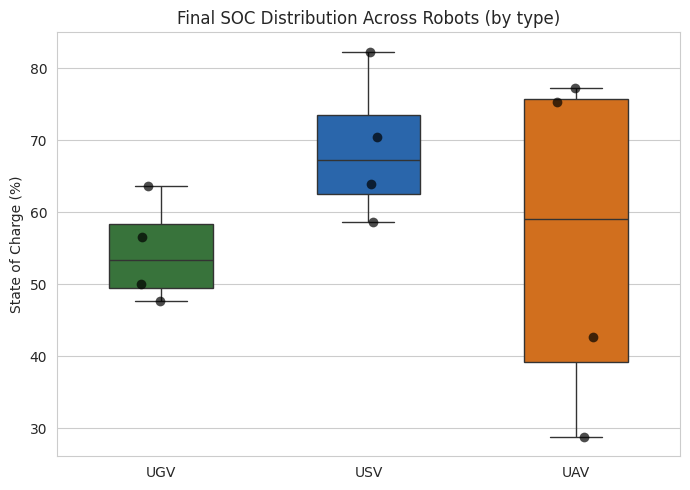

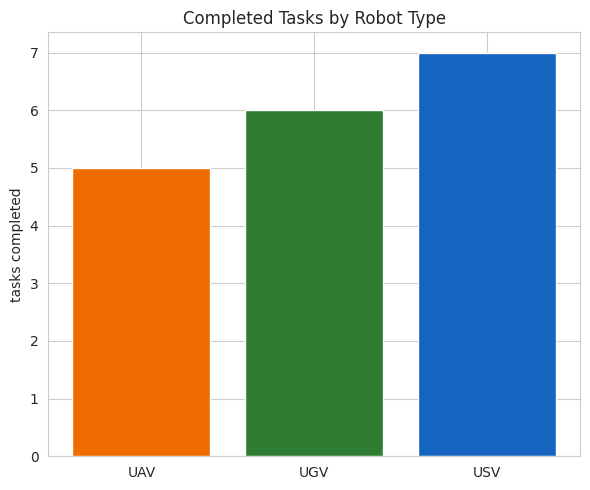

In [11]:
plot_soc_distribution(sim, savepath=f"{RESULTS_DIR}/day5_g15_soc_distribution.png")
plt.show()

plot_allocation_distribution_by_type(sim, savepath=f"{RESULTS_DIR}/day5_g16_allocation_by_type.png")
plt.show()


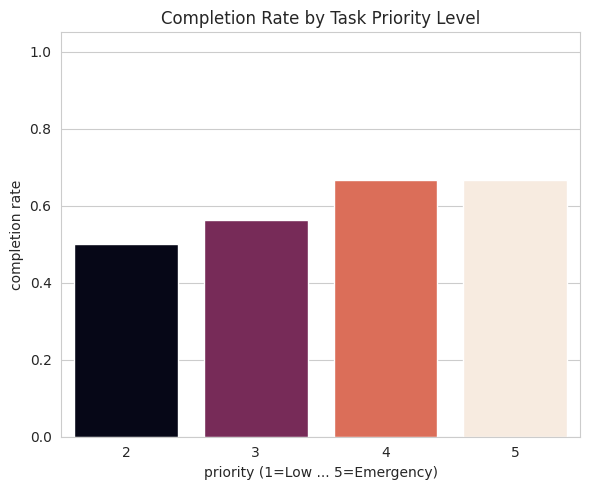

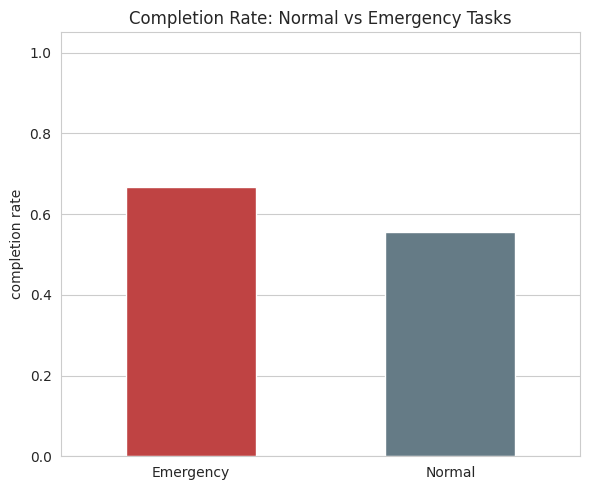

In [12]:
plot_priority_level_completion(sim, savepath=f"{RESULTS_DIR}/day5_g17_priority_completion.png")
plt.show()

plot_normal_vs_emergency(sim, savepath=f"{RESULTS_DIR}/day5_g18_normal_vs_emergency.png")
plt.show()


### Average SOC and battery degradation (SOH) over time

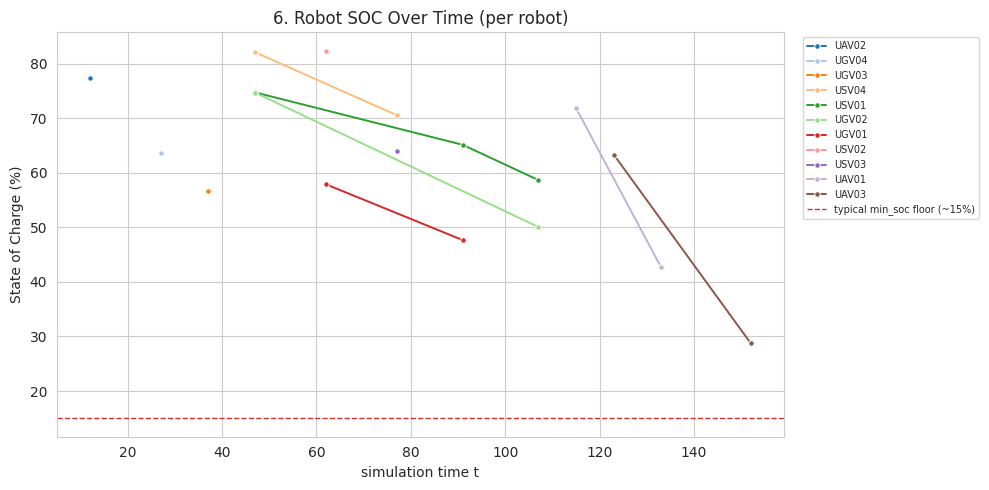

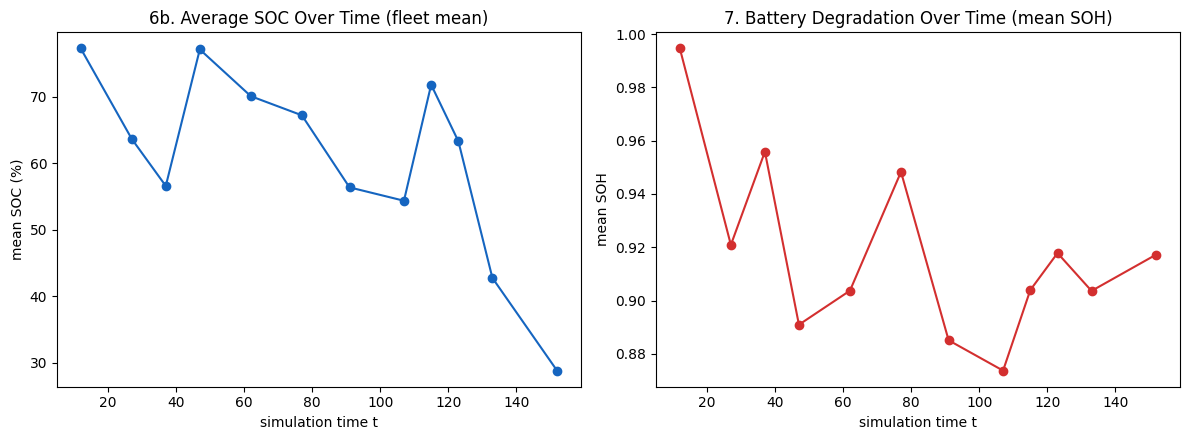

In [13]:
rh = pd.read_csv("../data/dataset/simulation/robot_state_history.csv")
rh_run = rh[rh.run_id == "notebook13_breakdown"].sort_values("t")

plot_robot_soc_timeline(rh, run_id="notebook13_breakdown",
                          title="6. Robot SOC Over Time (per robot)",
                          savepath=f"{RESULTS_DIR}/day5_g06_soc_over_time.png")
plt.show()

avg_by_t = rh_run.groupby("t")[["soc", "soh"]].mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(avg_by_t["t"], avg_by_t["soc"], marker="o", color="#1565c0")
axes[0].set_title("6b. Average SOC Over Time (fleet mean)")
axes[0].set_xlabel("simulation time t"); axes[0].set_ylabel("mean SOC (%)")
axes[1].plot(avg_by_t["t"], avg_by_t["soh"], marker="o", color="#d32f2f")
axes[1].set_title("7. Battery Degradation Over Time (mean SOH)")
axes[1].set_xlabel("simulation time t"); axes[1].set_ylabel("mean SOH")
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/day5_g07_battery_degradation.png", dpi=150, bbox_inches="tight")
plt.show()


## Day 5 status — complete, project complete

- [x] Section 26: 4 baselines + proposed system compared, 5 seeds
- [x] Section 27: 9-step ablation ladder + separate-track GAT-PPO row
- [x] Section 28: Scenarios A-G (3 seeds) + Scenario H scalability (3 seeds, 5 sizes)
- [x] Section 29: full metrics module (allocation/time/energy/fairness/path/risk/compute)
- [x] Section 30: all 19+ required publication-quality graphs generated above,
      every one from real executed-simulation data
- [x] Section 32: seeded, reproducible (documented seed lists throughout)

**All 5 days of the project plan are now complete.** See the project
README for the full status table, known limitations, and the two bugs
found and fixed during verification.